In [1]:
import pandas as pd
import numpy as np

import matplotlib as mpl
import matplotlib.dates as mdates
import matplotlib.pyplot as plt

mpl.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
    "text.latex.preamble": r"\usepackage{amsmath}\usepackage{amssymb}\usepackage{times}",
})
# Set global default sizes for both standard titles and super titles
plt.rcParams['font.size'] = 16
plt.rcParams['figure.titlesize'] = 18  # For fig.suptitle

from datetime import datetime
from scipy.stats import linregress, t as t_dist
from scipy.ndimage import gaussian_filter
from scipy.signal import detrend

from pathlib import Path

from das_tools.utils import proj_path
from das_tools.processing import pisces25


PROJECT_ROOT = proj_path.find_project_root()

DATA_DIR = proj_path.data_dir()
WIND_FILE = proj_path.data_dir("SWIFT19_telemetry.nc")
SEIS_DIR = proj_path.output_dir("seismometer")   # welch_pca_results_N?.csv

OUT = proj_path.output_dir("bf_inv_disp")
OUT_DISP = OUT / "disp_curves"
OUT_SUMMARY = OUT / "summary"

FIG_MAIN = proj_path.figures_dir("main_text")
FIG_DIR = FIG_MAIN / "8_directional"

csv_path = DATA_DIR / "bend_change_shortest.csv"
disp_path = OUT_DISP / "disp_cache_0.10-1.00Hz.npz"


disp_details = np.load(disp_path)
theta = disp_details["theta"]

F1, F2 = 0.10,1.00
STATS_NPZ = OUT_SUMMARY /"theta_fixed_omni_skip2_coh_f0.10-1.00Hz_llnone_theta294.0_hw5.npz"
#" f"timeseries_stats_omni_skip2_coh_f{F1:.2f}-{F2:.2f}Hz_llnone.npz"

print("stats file:", STATS_NPZ)
results = np.load(STATS_NPZ, allow_pickle=True)

t_all_global = pd.to_datetime(results["output_time_all"]).to_numpy(dtype="datetime64[ns]")

E_med_all = results[ "E_med_all"]
pk_freq_all = results[ "pk_freq_all"]
E_l68_all = results[ "E_l68_all"]
E_u68_all = results[ "E_u68_all"]
E_l95_all = results[ "E_l95_all"]
E_u95_all = results[ "E_u95_all"]
P_med_all = results["P_med_all"]
P_l68_all = results[ "P_l68_all"]
P_u68_all = results[ "P_u68_all"]
P_l95_all = results[ "P_l95_all"]
P_u95_all = results[ "P_u95_all"]

# Every block is conditioned on the theta-fix window (289-299 deg) in step 3,
# so no block is selected by azimuth; drop only blocks without a posterior.
mask_valid = np.isfinite(E_med_all) & np.isfinite(P_med_all)

# ------------------------------------------------------------
# (E, P) hypothesis grid the inversion searched, in plotting units.
# The stats file's own grids win when it carries them, since the joint
# log-likelihood below is indexed on exactly that grid.
# ------------------------------------------------------------
E_g = (results["E_grid_GPa"] if "E_grid_GPa" in results.files
       else np.asarray(disp_details["E_all"], dtype=float) / 1e9)
P_m = (results["P_grid_MPa"] if "P_grid_MPa" in results.files
       else np.asarray(disp_details["P_all"], dtype=float) / 1e6)

E_g = np.asarray(E_g, dtype=float)
P_m = np.asarray(P_m, dtype=float)


# ------------------------------------------------------------
# Monte Carlo propagation of the per-window posteriors through the
# moving mean, following notebooks/bf_inv_new/mainSeriesAndStat_curveLL_22.ipynb.
#
# The old figure smoothed the per-window point estimates (the medians) with a
# rolling mean, which throws away every window's uncertainty and its E-P
# correlation. Instead each window's joint posterior p_t(E, P) is sampled, the
# draws are averaged inside the moving window, and the moving mean is reported
# as the MAP of that averaged posterior with a credible band around it.
# ------------------------------------------------------------
N_MC = 4000            # joint (E, P) draws kept per window
MC_SEED = 20250425
MC_ESS_RATIO = 1.0     # N / N_eff; > 1 widens the bands for correlated windows
LIKELIHOOD_TEMPERATURE = 1.0   # > 1 broadens each per-window posterior

time_w, wind_speed = pisces25.retrieve_wind_swift(WIND_FILE)


stats file: /Users/junsuj/Desktop/git/das-landfast-ice-inversion2025/outputs/bf_inv_disp/summary/theta_fixed_omni_skip2_coh_f0.10-1.00Hz_llnone_theta294.0_hw5.npz


In [2]:
# ------------------------------------------------------------------
# Per-window joint (E, P) posteriors, and Monte Carlo draws from them
#
# Mirrors `posterior_from_LL` / `sample_joint_posterior` in
# notebooks/bf_inv_new/mainSeriesAndStat_curveLL_22.ipynb. A uniform prior over
# the searched grid is assumed, so the posterior is a softmax of the joint
# log-likelihood over the scored cells.
# ------------------------------------------------------------------

# Names the processor may have used for the per-window joint array, in
# preference order. Add yours here rather than renaming the file.
JOINT_LL_KEYS = (
    "logL_EP_all", "LL_EP_all", "logL_EP", "LL_EP",
    "logLike_EP_all", "logPost_EP_all", "LP_EP_all",
    "joint_LL_all", "LL_joint_all",
)
JOINT_POST_KEYS = (
    "post_EP_all", "p_EP_all", "posterior_EP_all", "post_ep_all",
)


def _orient_joint(A, n_win, nE, nP, valid_ep=None, fill=np.nan):
    """Coerce a stored joint array to (n_windows, nE, nP).

    `valid_ep` is the (nE, nP) boolean mask of scored cells. The inversion
    scores only the valid (E, P) pairs and carries them compressed, so an
    array whose trailing axis is valid_ep.sum() is scattered back onto the
    full grid here, with `fill` everywhere the curve solver never scored.
    """
    A = np.asarray(A, dtype=float)

    if valid_ep is not None and A.ndim == 2 and A.shape == (n_win, int(valid_ep.sum())):
        out = np.full((n_win, nE, nP), fill, dtype=float)
        out[:, valid_ep] = A
        return out

    if A.ndim == 2 and A.shape == (n_win, nE * nP):
        return A.reshape(n_win, nE, nP)

    if A.ndim != 3:
        raise ValueError(
            f"joint array has shape {A.shape}; expected "
            f"({n_win}, {nE}, {nP}) or ({n_win}, {nE * nP})")

    if A.shape[0] != n_win:
        raise ValueError(
            f"joint array has {A.shape[0]} windows but the series has {n_win}; "
            "the stats file and the joint posteriors are out of step")

    if A.shape[1:] == (nE, nP):
        return A
    if A.shape[1:] == (nP, nE):
        # Stored (P, E); the plotting code below is written for (E, P).
        return np.transpose(A, (0, 2, 1))

    raise ValueError(
        f"joint array grid is {A.shape[1:]}, but the (E, P) grid is "
        f"({nE}, {nP}). Check E_grid_GPa / P_grid_MPa in the stats file, and "
        "that valid_disp matches the mask the inversion compressed against.")


def load_joint_posteriors(results, n_win, E_g, P_m, valid_ep=None,
                          temperature=LIKELIHOOD_TEMPERATURE, verbose=True):
    """Per-window joint posterior on the (E, P) grid, shape (n_win, nE, nP).

    Accepts either a joint log-likelihood (converted by a tempered softmax) or
    an already-normalized joint posterior. Returns None when the stats file
    carries neither, which leaves the notebook on the old point-estimate
    smoothing rather than failing outright.
    """
    nE, nP = E_g.size, P_m.size
    files = set(results.files)

    # The scored-cell mask, so a compressed valid-EP array can be expanded.
    if valid_ep is None:
        for k in ("valid_disp", "valid_ep", "scored_mask"):
            if k in files and np.shape(results[k]) == (nE, nP):
                valid_ep = np.asarray(results[k], dtype=bool)
                break
        else:
            vd = np.asarray(disp_details["valid_disp"], dtype=bool)
            valid_ep = vd if vd.shape == (nE, nP) else None

    key = next((k for k in JOINT_LL_KEYS if k in files), None)
    if key is not None:
        # -inf, not NaN, off the scored set: an unscored cell has zero
        # likelihood, and NaN would poison the softmax's max.
        LL = _orient_joint(results[key], n_win, nE, nP, valid_ep, fill=-np.inf)
        if verbose:
            print(f"joint log-likelihood from '{key}', shape {LL.shape}, "
                  f"temperature {temperature:g}")

        finite = np.isfinite(LL)
        scaled = np.where(finite, LL / temperature, -np.inf)
        m = np.max(np.where(finite, scaled, -np.inf), axis=(1, 2), keepdims=True)
        m = np.where(np.isfinite(m), m, 0.0)

        post = np.where(finite, np.exp(scaled - m), 0.0)
    else:
        key = next((k for k in JOINT_POST_KEYS if k in files), None)
        if key is None:
            if verbose:
                print("no joint (E, P) posterior in the stats file "
                      f"(looked for {', '.join(JOINT_LL_KEYS + JOINT_POST_KEYS)});"
                      "\nfalling back to the moving mean of the per-window medians")
            return None

        post = _orient_joint(results[key], n_win, nE, nP, valid_ep, fill=0.0)
        post = np.where(np.isfinite(post) & (post > 0), post, 0.0)
        if verbose:
            print(f"joint posterior from '{key}', shape {post.shape}")

    total = post.sum(axis=(1, 2), keepdims=True)
    post = np.divide(post, total, out=np.zeros_like(post), where=total > 0)

    empty = np.squeeze(total <= 0)
    if verbose and np.any(empty):
        print(f"{int(np.sum(empty))} of {n_win} windows carry no posterior mass")

    return post


def sample_joint_posterior(E_g, P_m, post_ep, n_samples, rng):
    """Draw n_samples (E, P) pairs from one window's joint posterior.

    Sampling the *joint* rather than the two marginals is the point: E and P
    trade off along a ridge, so independent marginal draws would invent (E, P)
    pairs the posterior all but excludes. Draws land on grid nodes.
    """
    flat = np.asarray(post_ep, dtype=float).ravel()
    total = flat.sum()
    if not np.isfinite(total) or total <= 0:
        return np.full((n_samples, 2), np.nan)

    cdf = np.cumsum(flat / total)
    cdf[-1] = 1.0   # guard the last cell against floating-point shortfall
    idx = np.searchsorted(cdf, rng.random(n_samples), side="left")
    i, j = np.unravel_index(np.clip(idx, 0, flat.size - 1), post_ep.shape)

    return np.column_stack((E_g[i], P_m[j]))


n_win = len(t_all_global)
post_ep_all = load_joint_posteriors(results, n_win, E_g, P_m)

if post_ep_all is None:
    ep_samples = None
else:
    rng = np.random.default_rng(MC_SEED)

    # Blocks without a posterior stay NaN and cost nothing to draw.
    to_sample = mask_valid

    ep_samples = np.full((n_win, N_MC, 2), np.nan)
    for i in np.flatnonzero(to_sample):
        ep_samples[i] = sample_joint_posterior(E_g, P_m, post_ep_all[i], N_MC, rng)

    n_drawn = int(np.isfinite(ep_samples[:, 0, 0]).sum())
    print(f"{N_MC} joint (E, P) draws for {n_drawn} of {n_win} windows "
          f"({ep_samples.nbytes / 1e6:.0f} MB), seed {MC_SEED}")

    # The joint MAP of each individual window, for reference against the
    # moving-mean MAP the figure plots.
    flat_map = np.argmax(post_ep_all.reshape(n_win, -1), axis=1)
    i_map, j_map = np.unravel_index(flat_map, post_ep_all.shape[1:])
    E_joint_map = E_g[i_map]
    P_joint_map = P_m[j_map]

joint log-likelihood from 'logL_EP_all', shape (598, 98, 26), temperature 1
4000 joint (E, P) draws for 598 of 598 windows (38 MB), seed 20250425


In [3]:
def add_contiguous_segments(df, time_col="time", max_gap_hours=1.5):
    """
    Assign a segment ID to contiguous time series chunks.
    A new segment starts whenever the gap exceeds max_gap_hours.
    """
    df = df.sort_values(time_col).copy()

    dt_hr = df[time_col].diff().dt.total_seconds() / 3600.0
    new_segment = dt_hr.isna() | (dt_hr > max_gap_hours)

    df["segment"] = np.cumsum(new_segment.to_numpy()) - 1
    return df


def moving_average_by_segment(
    t,
    y,
    mask,
    window_hours=3,
    max_gap_hours=1.5,
    min_periods=2,
):
    """
    Compute time-based moving average of y within contiguous valid segments only.

    This is the old estimator, kept as the fallback for when the stats file
    carries no joint posterior. It smooths the per-window point estimates and
    therefore says nothing about how well the smoothed value is known;
    `moving_joint_map_and_bands` below is what the figure uses when the
    posteriors are available.

    Parameters
    ----------
    t : array-like
        Time vector.

    y : array-like
        Median values to smooth.

    mask : bool array
        Valid-data mask.

    window_hours : float
        Moving-average window length.

    max_gap_hours : float
        Gaps longer than this start a new segment.

    min_periods : int
        Minimum number of samples required in a moving window.

    Returns
    -------
    df_smooth : DataFrame
        Columns: time, y, y_smooth, segment
    """
    df = pd.DataFrame({
        "time": pd.to_datetime(np.asarray(t)[mask]),
        "y": np.asarray(y, dtype=float)[mask],
    }).dropna(subset=["time", "y"]).sort_values("time")

    if df.empty:
        return df

    df = add_contiguous_segments(
        df,
        time_col="time",
        max_gap_hours=max_gap_hours,
    )

    win = f"{window_hours}h"

    pieces = []
    for _, g in df.groupby("segment"):
        g = g.set_index("time").sort_index()

        g["y_smooth"] = (
            g["y"]
            .rolling(win, center=True, min_periods=min_periods)
            .mean()
        )

        g = g.reset_index()
        pieces.append(g)

    df_smooth = pd.concat(pieces, ignore_index=True)
    return df_smooth


def moving_joint_map_and_bands(
    t,
    ep_samples,
    mask,
    window_hours,
    max_gap_hours=1.0,
    min_periods=2,
    n_bins=(80, 80),
    smooth_sigma=1.0,
    ess_ratio=1.0,
):
    """
    Propagate the joint per-window posteriors through a moving average.

    Every window carries a full joint posterior p_t(E, P), so the moving mean
    of the underlying states is itself a random variable with posterior

        p(Ebar, Pbar | d) = int delta(xbar - (1/N) sum_t x_t)
                            prod_t p_t(x_t | d_t) dx_1 ... dx_N,

    evaluated here by Monte Carlo: realization b uses draw b from every window
    in the window, so each realization is one self-consistent path through the
    record and the E-P ridge is respected.

    Parameters
    ----------
    t : array-like
        Time values, convertible to datetime64.
    ep_samples : ndarray
        Shape (n_time, n_mc, 2), with columns (E, P).
    mask : ndarray
        Boolean mask selecting accepted windows.
    window_hours : float
        Width of the centered moving window.
    max_gap_hours : float
        Do not average across gaps larger than this.
    min_periods : int
        Minimum number of accepted windows required in a moving window.
    ess_ratio : float
        N / N_eff. Consecutive windows overlap in data and the ice state
        evolves smoothly, so independent draws make the band too narrow;
        this widens both intervals by sqrt(N / N_eff). 1.0 is the
        optimistic reading.

    Returns
    -------
    out : dict
        Moving-average posterior MAP, credible intervals, and samples.
    """
    t = np.asarray(t).astype("datetime64[ns]")
    ep_samples = np.asarray(ep_samples, dtype=float)
    mask = np.asarray(mask, dtype=bool)

    n_time, n_mc, n_param = ep_samples.shape
    assert n_param == 2

    t_hours = t.astype("datetime64[s]").astype(np.int64) / 3600.0

    half_window = window_hours / 2.0

    # Windows with any non-finite draw carry no posterior and never enter.
    usable = mask & np.all(np.isfinite(ep_samples), axis=(1, 2))

    out_time = []
    moving_samples = []

    for i in range(n_time):
        if not usable[i]:
            continue

        # Centered moving window
        in_window = (
            (t_hours >= t_hours[i] - half_window)
            & (t_hours <= t_hours[i] + half_window)
            & usable
        )

        inds = np.flatnonzero(in_window)

        if len(inds) < min_periods:
            continue

        # Do not average across a large temporal gap
        if np.any(np.diff(t_hours[inds]) > max_gap_hours):
            continue

        # The same MC index across all windows preserves the joint E-P
        # relationship in each Monte Carlo moving average.
        mov = np.mean(ep_samples[inds], axis=0)      # (n_mc, 2)

        out_time.append(t[i])
        moving_samples.append(mov)

    if not moving_samples:
        raise ValueError("No valid moving windows were found.")

    moving_samples = np.asarray(moving_samples)
    out_time = np.asarray(out_time)

    # Break the moving-average line and uncertainty band across gaps.
    out_hours = out_time.astype("datetime64[s]").astype(np.int64) / 3600.0

    segments = np.zeros(len(out_time), dtype=int)
    if len(out_time) > 1:
        segments[1:] = np.cumsum(np.diff(out_hours) > max_gap_hours)

    scale = np.sqrt(float(ess_ratio))

    E_center = np.mean(moving_samples[:, :, 0], axis=1)
    P_center = np.mean(moving_samples[:, :, 1], axis=1)

    E_wide = E_center[:, None] + scale * (moving_samples[:, :, 0] - E_center[:, None])
    P_wide = P_center[:, None] + scale * (moving_samples[:, :, 1] - P_center[:, None])

    E_lo, E_hi = np.percentile(E_wide, [5, 95], axis=1)
    P_lo, P_hi = np.percentile(P_wide, [5, 95], axis=1)

    E_lo1sd, E_hi1sd = np.percentile(E_wide, [15.865, 84.135], axis=1)
    P_lo1sd, P_hi1sd = np.percentile(P_wide, [15.865, 84.135], axis=1)

    # 2D MAP of p(Ebar, Pbar) for every moving window. This is the mode of the
    # averaged posterior, not the moving average of the per-window MAPs.
    map_E = np.full(len(out_time), np.nan)
    map_P = np.full(len(out_time), np.nan)

    for k in range(len(out_time)):
        xy = moving_samples[k]

        if np.ptp(xy[:, 0]) == 0 or np.ptp(xy[:, 1]) == 0:
            map_E[k] = np.median(xy[:, 0])
            map_P[k] = np.median(xy[:, 1])
            continue

        e_edges = np.linspace(xy[:, 0].min(), xy[:, 0].max(), n_bins[0] + 1)
        p_edges = np.linspace(xy[:, 1].min(), xy[:, 1].max(), n_bins[1] + 1)

        H, _, _ = np.histogram2d(xy[:, 0], xy[:, 1],
                                 bins=(e_edges, p_edges), density=True)

        # Light smoothing makes the estimated mode less sensitive to
        # individual Monte Carlo samples.
        H_smooth = gaussian_filter(H, sigma=smooth_sigma)

        i_e, i_p = np.unravel_index(np.argmax(H_smooth), H_smooth.shape)

        map_E[k] = 0.5 * (e_edges[i_e] + e_edges[i_e + 1])
        map_P[k] = 0.5 * (p_edges[i_p] + p_edges[i_p + 1])

    return {
        "time": out_time,
        "segment": segments,
        "samples": moving_samples,

        "E_map": map_E, "P_map": map_P,
        "E_lo": E_lo, "E_hi": E_hi,
        "P_lo": P_lo, "P_hi": P_hi,
        "E_lo1sd": E_lo1sd, "E_hi1sd": E_hi1sd,
        "P_lo1sd": P_lo1sd, "P_hi1sd": P_hi1sd,
        "E_mean": E_center, "P_mean": P_center,
    }


def bands_from_moving_joint(mov):
    """Split a moving_joint_map_and_bands result into an E band and a P band."""
    def one(prefix):
        return {
            "time": mov["time"],
            "segment": mov["segment"],
            "map": mov[f"{prefix}_map"],
            "mean": mov[f"{prefix}_mean"],
            "lo95": mov[f"{prefix}_lo"],
            "hi95": mov[f"{prefix}_hi"],
            "lo1sd": mov[f"{prefix}_lo1sd"],
            "hi1sd": mov[f"{prefix}_hi1sd"],
        }

    return one("E"), one("P")


def band_at_times(band, target_times, tol_hours=1.0):
    """
    Match moving-average uncertainty values to target timestamps.
    Returns the empirical 1-sigma-equivalent half-width.
    """
    bt = pd.to_datetime(np.asarray(band["time"]))
    target_times = pd.to_datetime(np.asarray(target_times))

    order = np.argsort(bt)
    bt = bt[order]

    lo1 = np.asarray(band["lo1sd"], dtype=float)[order]
    hi1 = np.asarray(band["hi1sd"], dtype=float)[order]

    bt_ns = bt.to_numpy(dtype="datetime64[ns]").astype("int64")
    target_ns = target_times.to_numpy(dtype="datetime64[ns]").astype("int64")

    pos = np.clip(np.searchsorted(bt_ns, target_ns), 0, len(bt_ns) - 1)

    # Also check the previous point when it is closer.
    prev = np.clip(pos - 1, 0, len(bt_ns) - 1)
    use_prev = np.abs(target_ns - bt_ns[prev]) < np.abs(target_ns - bt_ns[pos])
    idx = np.where(use_prev, prev, pos)

    distance_hours = np.abs(target_ns - bt_ns[idx]) / 3.6e12
    std = 0.5 * (hi1[idx] - lo1[idx])
    std[distance_hours > tol_hours] = np.nan

    return {
        "std": std,
        "lo1sd": lo1[idx],
        "hi1sd": hi1[idx],
        "distance_hours": distance_hours,
    }

In [4]:
def plot_binned_median_std_on_ax(
    ax,
    *,
    t,
    y,
    BF,
    mask,
    title,
    y_label,
    c_label,
    l68,
    u68,
    l95,
    u95,
    bin_hours=4,
    ymax=7.0,
    ymin=0,
    moving_average_hours=3,
    max_gap_hours=1.5,
    show_uncertainty=False,
    panel_label=None,
    show_xlabel=True,
    show_ylabel=True,
    show_legend=False,
    wind_time=None,
    wind_speed=None,
    show_wind=True,
    band=None,
    band_color="k",
    band_label=None,
    is_detrend=False
):
    """One time-series panel.

    `band` is the output of `moving_joint_map_and_bands`, split by
    `bands_from_moving_joint`: the posterior of the moving mean itself. When it
    is given, the black line is the MAP of that averaged posterior and the
    shaded region its 5-95% credible interval. When it is None the panel falls
    back to the old estimator, a rolling mean of the per-window medians.
    """
    # ------------------------------------------------------------
    # Optional uncertainty bars at original valid times
    #
    # These are the marginal per-window credible intervals -- a different
    # object from the band below, which is the uncertainty of the smoothed
    # quantity the line actually reports.
    # ------------------------------------------------------------
    if show_uncertainty:
        t_mask = pd.to_datetime(np.asarray(t)[mask])
        l68_mask = np.asarray(l68, dtype=float)[mask]
        u68_mask = np.asarray(u68, dtype=float)[mask]

        for i in range(len(t_mask)):
            if np.isfinite(l68_mask[i]) and np.isfinite(u68_mask[i]):
                ax.vlines(
                    t_mask[i],
                    l68_mask[i],
                    u68_mask[i],
                    color="lightskyblue",
                    alpha=0.25,
                    linewidth=2.0,
                    zorder=1,
                )

    # ------------------------------------------------------------
    # Moving average of the posterior: MAP of p(param_bar | d) with its
    # credible band, filled per contiguous segment so both stop at a gap.
    # ------------------------------------------------------------
    if band is not None:
        bt = pd.to_datetime(band["time"])
        bseg = np.asarray(band.get("segment", np.zeros(len(bt), dtype=int)))

        if band_label is None:
            band_label = rf"{moving_average_hours:g}-hr moving window resampling"

        first = True

        for s in np.unique(bseg):
            m = bseg == s

            if m.sum() < 2:
                continue

            ax.fill_between(
                bt[m],
                band["lo95"][m],
                band["hi95"][m],
                color=band_color,
                alpha=0.3,
                linewidth=0,
                zorder=1.5,
                label=r"90\% credible interval" if first else None,
            )


            # The MAP of p(E_bar, P_bar | data) projected onto the plotted
            # parameter, not the moving average of the per-window MAPs.
            if is_detrend:
                b = detrend(band["map"][m])
            else:
                b = band["map"][m]

            ax.plot(
                bt[m],
                b,
                color="black",
                linewidth=2.0,
                zorder=4.5,
                label=f"MAP from {band_label}" if first else None,
            )

            first = False


    # ------------------------------------------------------------
    # Main axis formatting
    # ------------------------------------------------------------
    ax.set_title(title, pad=8)
    ax.set_ylim([ymin, ymax])
    ax.grid(True, alpha=0.35)

    ax.set_xlim([
        datetime(2025, 4, 24),
        datetime(2025, 5, 8),
    ])

    ax.xaxis.set_major_locator(mdates.AutoDateLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%m/%d"))

    if show_xlabel:
        ax.set_xlabel("Date (UTC)", labelpad=8)
    else:
        ax.set_xlabel("")
        ax.tick_params(labelbottom=False)

    if show_ylabel:
        ax.set_ylabel(y_label, labelpad=8)
    else:
        ax.set_ylabel("")

    if show_legend:
        ax.legend(loc="upper right", frameon=True)

    # ------------------------------------------------------------
    # Panel label
    # ------------------------------------------------------------
    if panel_label is not None:
        ax.text(
            0.015,
            0.96,
            panel_label,
            transform=ax.transAxes,
            ha="left",
            va="top",
            fontsize=13,
            fontweight="bold",
            bbox=dict(facecolor="white", edgecolor="none", alpha=0.75),
            zorder=10,
        )

    # ------------------------------------------------------------
    # Right axis: wind speed
    # ------------------------------------------------------------
    ax2 = None

    if show_wind and wind_time is not None and wind_speed is not None:
        ax2 = ax.twinx()

        ax2.plot(
            pd.to_datetime(wind_time),
            wind_speed**2,
            linewidth=1.2,
            color="tab:blue",
            alpha=0.75,
            label="Wind $^2$",
        )

        ax2.set_ylabel("Wind Speed$^2$, $U^2$ ((m/s)$^2$", color="tab:blue", labelpad=8)
        ax2.set_ylim([0, 130])
        ax2.set_yticks(range(0,131,20))
        ax2.tick_params(axis="y", labelcolor="tab:blue")

    return ax2

In [ ]:
def gapped_autocorrelation(z, max_lag):
    """Autocorrelation rho(1..max_lag) of a regularly gridded series with NaN gaps.

    Each lag uses only the pairs where both values exist; rho[0] is unused.
    """
    z = np.asarray(z, dtype=float) - np.nanmean(z)
    var = np.nanmean(z ** 2)
    rho = np.full(max_lag + 1, np.nan)
    for j in range(1, max_lag + 1):
        prod = z[:-j] * z[j:]
        if np.isfinite(prod).sum() > 1:
            rho[j] = np.nanmean(prod) / var
    return rho


def effective_sample_size(t, x, y, cadence_hours, max_lag=None):
    """Effective number of independent (x, y) pairs for a correlation.

    Pyper & Peterman (1998, eq. 1)

        1/N_eff = 1/N + (2/N) sum_{j=1}^{J} ((N - j)/N) rho_xx(j) rho_yy(j),

    with the autocorrelations taken on the regular `cadence_hours` grid (gaps
    left as NaN, so a lag never bridges a gap as if it were one step) and
    J = N/5 lags by default, as Pyper & Peterman recommend. Capped at N.
    """
    t = pd.to_datetime(np.asarray(t))
    k = np.rint((t - t.min()) / pd.Timedelta(hours=cadence_hours)).astype(int)
    x_grid = np.full(k.max() + 1, np.nan)
    y_grid = np.full(k.max() + 1, np.nan)
    x_grid[k] = x
    y_grid[k] = y

    n = len(x)
    J = n // 5 if max_lag is None else int(max_lag)
    rho_x = gapped_autocorrelation(x_grid, J)
    rho_y = gapped_autocorrelation(y_grid, J)

    j = np.arange(1, J + 1)
    inv = 1.0 / n + (2.0 / n) * np.nansum(((n - j) / n) * rho_x[1:] * rho_y[1:])
    return min(float(n), 1.0 / inv)


def correlation_pvalue(r, n_eff):
    """Two-sided p-value of Pearson r with n_eff - 2 degrees of freedom."""
    if n_eff <= 2:
        return np.nan
    t_stat = r * np.sqrt((n_eff - 2) / (1 - r ** 2))
    return 2 * t_dist.sf(abs(t_stat), n_eff - 2)


def moving_correlation_param_wind_on_ax(
    ax,
    *,
    t_P,
    param,
    param_name,
    mask,
    time_w,
    wind_speed,
    window_hours=6,
    use_wind_squared=True,
    min_periods=2,
    max_gap_hours=None,
    title=None,
    ylabel=None,
    ylim=(0.2, 0.8),
    panel_label=None,
    verbose=True,
    show_ylabel=True,
    show_legend=True,
    yerr_band=None,
    yerr_tol_hours=1.0,
    smooth_param=False,
    scatter_label=None,
    is_detrend=False,
    show_xlabel=False,
    neff_cadence_hours=0.5,
):
    """Regress the parameter on wind forcing, and plot it.

    With `smooth_param=False` the values passed in are used as they are -- that
    is the mode to use when `param` is already the moving average of the
    posterior (`moving_joint_map_and_bands`), since re-smoothing it would apply
    the window twice. `smooth_param=True` restores the old behaviour, a rolling
    mean of the per-window point estimates.

    `yerr_band` is a band from `bands_from_moving_joint`; when given, each point
    carries the +/-1 sigma uncertainty of the moving mean at that time. The bars
    are drawn, not fitted -- an errors-in-variables fit would also need the
    uncertainty on the wind.

    The p-value uses the effective sample size (`effective_sample_size`), not
    N: successive windows and the wind are autocorrelated, so the nominal
    `linregress` p-value would treat near-duplicate points as independent.
    `neff_cadence_hours` is the spacing of the points being regressed.
    """
    df_P = pd.DataFrame({
        "time": pd.to_datetime(t_P),
        "param": np.asarray(param, dtype=float),
        "mask": np.asarray(mask, dtype=bool),
    })

    df_P = (
        df_P[df_P["mask"]]
        .dropna(subset=["time", "param"])
        .sort_values("time")
        .copy()
    )
    if is_detrend:
        df_P["param_detrended"] = detrend(df_P["param"].to_numpy())
    else:
        df_P["param_detrended"] = df_P["param"]

    df_w = pd.DataFrame({
        "time": pd.to_datetime(time_w),
        "wind": np.asarray(wind_speed, dtype=float),
    })

    df_w = (
        df_w
        .dropna(subset=["time", "wind"])
        .sort_values("time")
        .copy()
    )

    if df_P.empty:
        raise ValueError("df_P is empty after mask/dropna.")

    if df_w.empty:
        raise ValueError("df_w is empty after dropna.")

    if use_wind_squared:
        df_w["forcing"] = df_w["wind"] ** 2
        forcing_label = r"Wind speed$^2$, $U^2$ ((m/s)$^2$)"
        x_symbol = r"U^2"
    else:
        df_w["forcing"] = df_w["wind"]
        forcing_label = r"Wind speed (m/s)"
        x_symbol = r"U"

    # More robust datetime-to-number conversion
    tP_num = df_P["time"].to_numpy(dtype="datetime64[ns]").astype("int64").astype(float)
    tw_num = df_w["time"].to_numpy(dtype="datetime64[ns]").astype("int64").astype(float)

    forcing_vals = df_w["forcing"].to_numpy(dtype=float)

    df_P["forcing"] = np.interp(
        tP_num,
        tw_num,
        forcing_vals,
        left=np.nan,
        right=np.nan,
    )

    n_before_interp = len(df_P)
    n_after_interp = df_P["forcing"].notna().sum()

    df = df_P.dropna(subset=["param_detrended", "forcing"]).copy()

    # Smooth inside contiguous segments only, matching the time-series panels:
    # a rolling window that spans a multi-hour gap mixes unrelated ice states.
    if max_gap_hours is not None:
        df = add_contiguous_segments(df, time_col="time", max_gap_hours=max_gap_hours)
    else:
        df["segment"] = 0

    df = df.set_index("time").sort_index()

    if verbose:
        print(f"\n{param_name}")
        print("P/parameter time range:", df_P["time"].min(), "to", df_P["time"].max())
        print("wind time range:       ", df_w["time"].min(), "to", df_w["time"].max())
        print("points before interpolation filter:", n_before_interp)
        print("points after interpolation filter: ", n_after_interp)
        print("points entering the fit:            ", len(df))
        print("window_hours:", window_hours)
        print("min_periods:", min_periods)
        print("smooth_param:", smooth_param, " segments:", df["segment"].nunique())

    if df.empty:
        raise ValueError(
            "No overlapping parameter/wind points after interpolation. "
            "Check wind lag sign and time ranges."
        )

    if smooth_param:
        win = f"{window_hours}h"

        pieces = []
        for _, g in df.groupby("segment"):
            g = g.sort_index().copy()

            g["param_smooth"] = (
                g["param_detrended"]
                .rolling(win, center=True, min_periods=min_periods)
                .mean()
            )

            g["forcing_smooth"] = (
                g["forcing"]
                .rolling(win, center=True, min_periods=min_periods)
                .mean()
            )

            pieces.append(g)

        df = pd.concat(pieces).sort_index()
    else:
        # `param` is already the moving average of the posterior; the wind is
        # simply interpolated to each of its times.
        df["param_smooth"] = df["param_detrended"]
        df["forcing_smooth"] = df["forcing"]

    df_fit = df.dropna(subset=["param_smooth", "forcing_smooth"]).copy()

    if verbose:
        print("points after rolling mean:", len(df_fit))

    if len(df_fit) < 2:
        raise ValueError(
            f"Only {len(df_fit)} usable smoothed points after rolling. "
            "Need at least 2 for linregress."
        )

    x = df_fit["forcing_smooth"].to_numpy(dtype=float)
    y = df_fit["param_smooth"].to_numpy(dtype=float)

    good = np.isfinite(x) & np.isfinite(y)
    x = x[good]
    y = y[good]
    df_fit = df_fit.iloc[np.where(good)[0]].copy()

    if len(x) < 2:
        raise ValueError("Fewer than 2 finite x/y points after filtering.")

    if np.nanmin(x) == np.nanmax(x):
        raise ValueError("All x values are identical after smoothing.")

    reg = linregress(x, y)

    n_eff = effective_sample_size(df_fit.index, x, y, neff_cadence_hours)
    p_eff = correlation_pvalue(reg.rvalue, n_eff)
    df_fit.attrs.update(n_eff=n_eff, p_eff=p_eff, p_nominal=reg.pvalue)

    if verbose:
        print(f"r = {reg.rvalue:.3f}, N = {len(x)}, N_eff = {n_eff:.1f}, "
              f"p_eff = {p_eff:.2g} (nominal p = {reg.pvalue:.2g})")

    x_line = np.linspace(np.nanmin(x), np.nanmax(x), 200)
    y_line = reg.intercept + reg.slope * x_line

    if yerr_band is not None:
        at = band_at_times(yerr_band, df_fit.index, yerr_tol_hours)
        ax.errorbar(
            x,
            y,
            yerr=at["std"],
            fmt="none",
            ecolor="0.45",
            elinewidth=1.0,
            capsize=0,
            alpha=0.7,
            zorder=1,
            label=r"$\pm 1\sigma$ (moving mean)",
        )
        if verbose:
            print(f"error bars: {int(np.isfinite(at['std']).sum())} of {len(x)} "
                  f"points matched to the MC band")

    if scatter_label is None:
        scatter_label = ("Smoothed samples" if smooth_param
                         else "Individual 30-min posterior estimates")

    ax.scatter(
        x,
        y,
        s=28,
        color="black",
        alpha=0.65,
        edgecolors="none",
        zorder=2,
        label=scatter_label,
    )

    ax.plot(
        x_line,
        y_line,
        color="red",
        linewidth=2.0,
        label="Linear fit",
    )

    annotation = (
        rf"${param_name} = {reg.slope:.4f}{x_symbol} + {reg.intercept:.3f}$" "\n"
        rf"$r = {reg.rvalue:.2f}$, $R^2 = {reg.rvalue**2:.2f}$" "\n"
        rf"$N = {len(df_fit)}$, $N_\mathrm{{eff}} = {n_eff:.0f}$, $p = {p_eff:.2g}$"
    )

    ax.text(
        0.04,
        0.96,
        annotation,
        transform=ax.transAxes,
        ha="left",
        va="top",
        fontsize=13,
        bbox=dict(facecolor="white", edgecolor="black", alpha=0.8),
    )

    if panel_label is not None:
        ax.text(
            0.92,
            0.90,
            panel_label,
            transform=ax.transAxes,
            ha="left",
            va="bottom",
            fontsize=13,
            fontweight="bold",
            bbox=dict(facecolor="white", edgecolor="none", alpha=0.75),
        )

    if show_xlabel:
        ax.set_xlabel(forcing_label)

    if ylim is not None:
        ax.set_ylim(list(ylim))

    if ylabel is None:
        ylabel = param_name

    if show_ylabel:
        ax.set_ylabel(ylabel)
    else:
        ax.set_ylabel("")

    if title is not None:
        ax.set_title(title)

    ax.grid(True, alpha=0.35)

    if show_legend:
        ax.legend(loc="lower right")

    return reg, df, df_fit

598 moving windows at 4 h; stat_smooth_hrs = 0.5 h < 2 x bin_hrs = 1 h, so the regression uses the raw 0.5 h posterior medians

E
P/parameter time range: 2025-04-23 18:30:00 to 2025-05-07 16:00:00
wind time range:        2025-04-25 00:10:19.999996672 to 2025-05-07 23:15:20.999996672
points before interpolation filter: 598
points after interpolation filter:  576
points entering the fit:             576
window_hours: 0.5
min_periods: 1
smooth_param: False  segments: 2
points after rolling mean: 576
r = 0.183, N = 576, N_eff = 76.1, p_eff = 0.11 (nominal p = 1e-05)

P
P/parameter time range: 2025-04-23 18:30:00 to 2025-05-07 16:00:00
wind time range:        2025-04-25 00:10:19.999996672 to 2025-05-07 23:15:20.999996672
points before interpolation filter: 598
points after interpolation filter:  576
points entering the fit:             576
window_hours: 0.5
min_periods: 1
smooth_param: False  segments: 2
points after rolling mean: 576
r = 0.373, N = 576, N_eff = 60.8, p_eff = 0.0031 (nomina

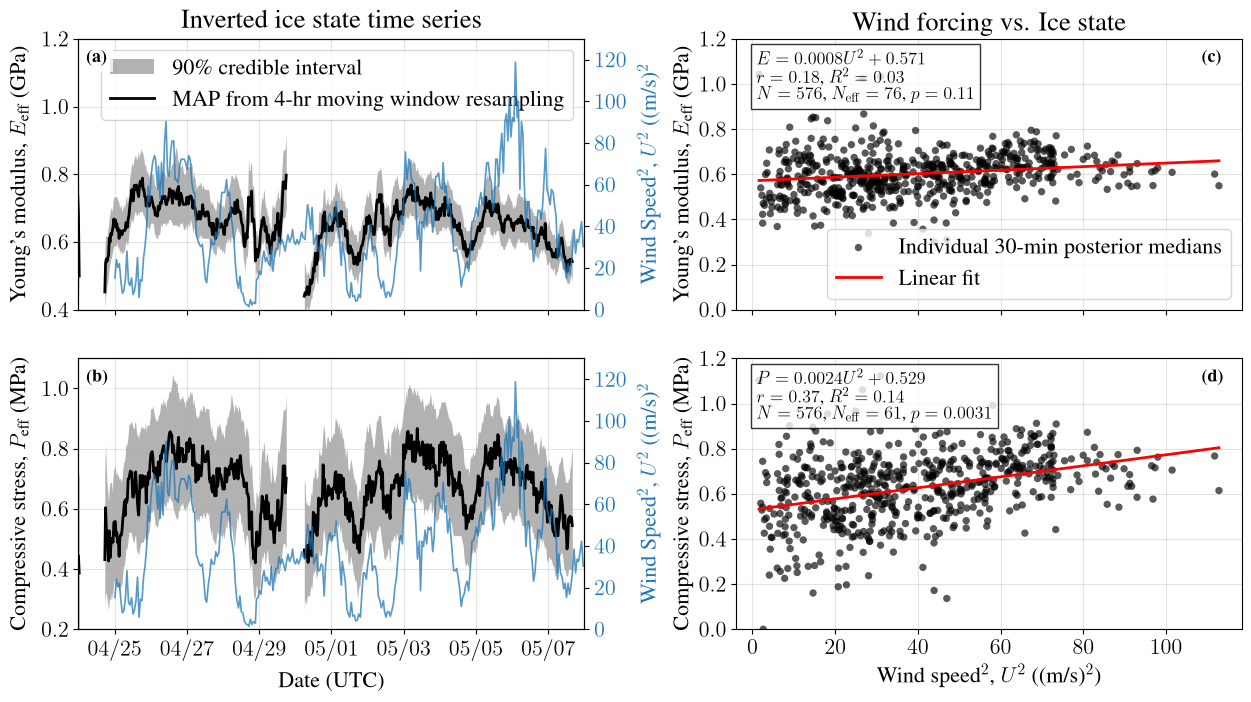

In [ ]:

# ------------------------------------------------------------
# Settings matching the existing notebooks
# ------------------------------------------------------------
bin_hrs = 0.5
smooth_hrs = 4        # moving window for the time-series panels
stat_smooth_hrs = .5   # < 2 x bin_hrs: the wind regression uses the unsmoothed
                       # 30-min posterior medians (see below)
max_gap_hrs = 2

lag = 0
time_w_lagged = pd.to_datetime(time_w) + pd.to_timedelta(
    lag, unit="h"
)

min_periods = max(
    .5,
    int(smooth_hrs / bin_hrs / 2),
)

y_label_E = r"Young's modulus, $E_\text{eff}$ (GPa)"
y_label_P = r"Compressive stress, $P_\text{eff}$ (MPa)"

# Stats-panel y limits. None lets each panel autoscale; the original stats
# notebook fixed both at (0.2, 0.8).
E_stat_ylim = (0.0, 1.2)
P_stat_ylim = (0.0, 1.2)


# ------------------------------------------------------------
# Moving average of the posterior
#
# Each retained window's joint posterior is sampled, the draws are averaged
# inside the moving window, and what the panels report is the MAP of that
# averaged posterior together with its credible band. The old behaviour --
# a rolling mean of the per-window medians -- is what runs if the stats file
# carries no joint posterior.
# ------------------------------------------------------------
if ep_samples is None:
    mov_ts = mov_stat = None
    E_band = P_band = None

    # Without posteriors the regression is the old one: a rolling mean of the
    # per-window medians over the same window as the time-series panels.
    t_stat = t_all_global
    E_stat, P_stat = E_med_all, P_med_all
    mask_stat = mask_valid
    smooth_param_stat = True
    stat_window_hrs = smooth_hrs
    stat_min_periods = min_periods
else:
    mov_ts = moving_joint_map_and_bands(
        t=t_all_global,
        ep_samples=ep_samples,
        mask=mask_valid,
        window_hours=smooth_hrs,
        max_gap_hours=max_gap_hrs,
        min_periods=2,
        ess_ratio=MC_ESS_RATIO,
    )

    E_band, P_band = bands_from_moving_joint(mov_ts)

    # A moving window narrower than two bins cannot average anything: it holds
    # at most one retained window, so smoothing it is meaningless (and with
    # min_periods=2 it would drop every point). In that case the regression
    # uses the unsmoothed per-window posterior medians at the native bin_hrs
    # cadence. Medians, not the per-window joint MAPs: the MAP sits on the
    # 0.1 GPa / 0.1 MPa grid, while the median is interpolated from the CDF.
    if stat_smooth_hrs < 2 * bin_hrs:
        mov_stat = None
        E_band_stat = P_band_stat = None

        t_stat = t_all_global
        E_stat, P_stat = E_med_all, P_med_all
        mask_stat = mask_valid
        smooth_param_stat = False
        stat_window_hrs = bin_hrs
        stat_min_periods = 1

        print(f"{len(mov_ts['time'])} moving windows at {smooth_hrs:g} h; "
              f"stat_smooth_hrs = {stat_smooth_hrs:g} h < 2 x bin_hrs = "
              f"{2 * bin_hrs:g} h, so the regression uses the raw "
              f"{bin_hrs:g} h posterior medians")
    else:
        mov_stat = moving_joint_map_and_bands(
            t=t_all_global,
            ep_samples=ep_samples,
            mask=mask_valid,
            window_hours=stat_smooth_hrs,
            max_gap_hours=max_gap_hrs,
            min_periods=2,
            ess_ratio=MC_ESS_RATIO,
        )

        E_band_stat, P_band_stat = bands_from_moving_joint(mov_stat)

        t_stat = mov_stat["time"]
        E_stat, P_stat = mov_stat["E_map"], mov_stat["P_map"]
        mask_stat = np.isfinite(E_stat) & np.isfinite(P_stat)
        smooth_param_stat = False
        stat_window_hrs = stat_smooth_hrs
        stat_min_periods = 2

        print(f"{len(mov_ts['time'])} moving windows at {smooth_hrs:g} h, "
              f"{len(mov_stat['time'])} at {stat_smooth_hrs:g} h")


# ------------------------------------------------------------
# Figure
# ------------------------------------------------------------
fig, axs = plt.subplots(
    2,
    2,
    figsize=(13.0, 7.2),
    constrained_layout=False,
)

ax_E_ts = axs[0, 0]
ax_P_ts = axs[1, 0]

ax_E_stat = axs[0, 1]
ax_P_stat = axs[1, 1]


# ============================================================
# LEFT COLUMN: 294-degree time series
# ============================================================

# ---- E ----
plot_binned_median_std_on_ax(
    ax_E_ts,
    t=t_all_global,
    y=E_med_all,
    BF=pk_freq_all,
    mask=mask_valid,

    title=r"Inverted ice state time series",
    y_label=y_label_E,
    c_label="Peak Frequency (Hz)",

    l68=E_l68_all,
    u68=E_u68_all,
    l95=E_l95_all,
    u95=E_u95_all,

    bin_hours=bin_hrs,
    ymax=1.2,
    ymin=0.4,

    moving_average_hours=smooth_hrs,
    max_gap_hours=max_gap_hrs,

    show_uncertainty=False,
    panel_label=r"\textbf{(a)}",

    show_xlabel=False,
    show_ylabel=True,
    show_legend=True,

    wind_time=time_w_lagged,
    wind_speed=wind_speed,
    show_wind=True,

    band=E_band,
)


# ---- P ----
plot_binned_median_std_on_ax(
    ax_P_ts,
    t=t_all_global,
    y=P_med_all,
    BF=pk_freq_all,
    mask=mask_valid,

    title="",
    y_label=y_label_P,
    c_label="Peak Frequency (Hz)",

    l68=P_l68_all,
    u68=P_u68_all,
    l95=P_l95_all,
    u95=P_u95_all,

    bin_hours=bin_hrs,
    ymax=1.1,
    ymin=0.2,

    moving_average_hours=smooth_hrs,
    max_gap_hours=max_gap_hrs,

    show_uncertainty=False,
    panel_label=r"\textbf{(b)}",

    show_xlabel=True,
    show_ylabel=True,
    show_legend=False,

    wind_time=time_w_lagged,
    wind_speed=wind_speed,
    show_wind=True,

    band=P_band,
)


# ============================================================
# RIGHT COLUMN: statistics vs wind forcing
#
# The regressed values are the 30-min posterior medians (or, with
# stat_smooth_hrs >= 2 x bin_hrs, the moving-average posterior MAPs), so
# smooth_param=False. The p-value uses N_eff, computed on the bin_hrs grid.
# ============================================================
stat_scatter_label = ("Individual 30-min posterior medians"
                      if mov_stat is None else None)

# ---- E vs U^2 ----
reg_E, df_E_smooth, df_E_fit = (
    moving_correlation_param_wind_on_ax(
        ax_E_stat,

        t_P=t_stat,
        param=E_stat,
        param_name="E",
        scatter_label=stat_scatter_label,
        neff_cadence_hours=bin_hrs,

        mask=mask_stat,

        time_w=time_w_lagged,
        wind_speed=wind_speed,

        window_hours=stat_window_hrs,
        use_wind_squared=True,
        min_periods=stat_min_periods,
        max_gap_hours=max_gap_hrs,

        title=r"Wind forcing vs. Ice state ",
        ylabel=y_label_E,
        ylim=E_stat_ylim,

        panel_label=r"\textbf{(c)}",

        verbose=True,
        show_ylabel=True,
        show_legend=True,

        smooth_param=smooth_param_stat,
        is_detrend = False,
    )
)


# ---- P vs U^2 ----
reg_P, df_P_smooth, df_P_fit = (
    moving_correlation_param_wind_on_ax(
        ax_P_stat,

        t_P=t_stat,
        param=P_stat,
        param_name="P",
        scatter_label=stat_scatter_label,
        neff_cadence_hours=bin_hrs,

        mask=mask_stat,

        time_w=time_w_lagged,
        wind_speed=wind_speed,

        window_hours=stat_window_hrs,
        use_wind_squared=True,
        min_periods=stat_min_periods,
        max_gap_hours=max_gap_hrs,

        title=None,
        ylabel=y_label_P,
        ylim=P_stat_ylim,

        panel_label=r"\textbf{(d)}",

        verbose=True,
        show_ylabel=True,
        show_legend=False,

        smooth_param=smooth_param_stat,
        is_detrend = False,
        show_xlabel=True
    )
)


# ============================================================
# Formatting
# ============================================================
# Align date axes in left column
ax_E_ts.sharex(ax_P_ts)

# Align forcing axes in right column
ax_E_stat.sharex(ax_P_stat)

# The right-column plots already have their own x labels.
# Suppress the top-row x labels.
ax_E_ts.tick_params(axis="x", labelbottom=False)
ax_E_stat.tick_params(axis="x", labelbottom=False)

# Leave a little more space between the two conceptual columns
fig.subplots_adjust(
    left=0.075,
    right=0.97,
    bottom=0.09,
    top=0.91,
    wspace=0.30,
    hspace=0.18,
)


# ------------------------------------------------------------
# Save
# ------------------------------------------------------------
outname = Path(
    f"figures/"
    f"E_P_timeseries_stats_294deg_"
    f"movpost{smooth_hrs}h_lag{lag}h.pdf"
)

outname.parent.mkdir(parents=True, exist_ok=True)

fig.savefig(
    outname,
    dpi=300,
    bbox_inches="tight",
)

plt.show()
plt.close(fig)


E-P linear correlation


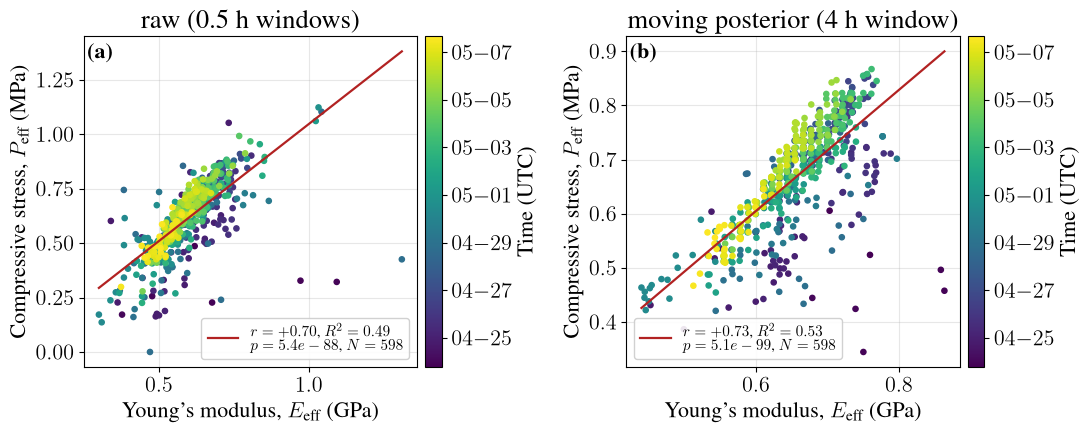

Saved: figures/E_P_correlation_movpost4h.pdf


In [7]:
# ------------------------------------------------------------
# Linear correlation between E and P
#
# E and P are inverted jointly from the same dispersion curve, so a
# correlation between them mixes a physical co-variation with the ridge the
# joint posterior has in the (E, P) plane. Two versions are reported:
#
#   * raw    -- the per-window medians kept by mask_valid, at the native
#               bin_hrs cadence.
#   * smooth -- the moving-average posterior MAPs the time-series panels
#               draw (smooth_hrs window), which are serially correlated, so
#               their p-value is optimistic.
# ------------------------------------------------------------
def _ep_linear_correlation(t, E, P, mask, label):
    """Pearson correlation of P on E over the valid samples."""
    E = np.asarray(E, dtype=float)
    P = np.asarray(P, dtype=float)
    ok = np.asarray(mask, dtype=bool) & np.isfinite(E) & np.isfinite(P)

    if ok.sum() < 3:
        print(f"{label}: fewer than 3 valid (E, P) pairs; skipped")
        return None

    reg = linregress(E[ok], P[ok])

    return {
        "reg": reg,
        "E": E[ok],
        "P": P[ok],
        "time": pd.to_datetime(np.asarray(t))[ok],
        "label": label,
    }


print("E-P linear correlation")

corr_raw = _ep_linear_correlation(
    t_all_global, E_med_all, P_med_all, mask_valid,
    f"raw ({bin_hrs:g} h windows)",
)

if mov_ts is None:
    corr_smooth = None
else:
    corr_smooth = _ep_linear_correlation(
        mov_ts["time"], mov_ts["E_map"], mov_ts["P_map"],
        np.isfinite(mov_ts["E_map"]) & np.isfinite(mov_ts["P_map"]),
        f"moving posterior ({smooth_hrs:g} h window)",
    )


# ------------------------------------------------------------
# Scatter, coloured by time, with the fitted line
# ------------------------------------------------------------
corr_panels = [c for c in (corr_raw, corr_smooth) if c is not None]

if corr_panels:
    fig_ep, axs_ep = plt.subplots(
        1,
        len(corr_panels),
        figsize=(5.6 * len(corr_panels), 4.6),
        squeeze=False,
    )

    for ax, corr, panel in zip(axs_ep[0], corr_panels,
                               [r"\textbf{(a)}", r"\textbf{(b)}"]):
        reg = corr["reg"]

        sc_ep = ax.scatter(
            corr["E"],
            corr["P"],
            c=mdates.date2num(corr["time"]),
            cmap="viridis",
            s=14,
            zorder=3,
        )

        x_fit = np.linspace(corr["E"].min(), corr["E"].max(), 100)

        ax.plot(
            x_fit,
            reg.intercept + reg.slope * x_fit,
            "-",
            color="firebrick",
            lw=1.6,
            zorder=4,
            label=(
                rf"$r = {reg.rvalue:+.2f}$, "
                rf"$R^2 = {reg.rvalue ** 2:.2f}$" "\n"
                rf"$p = {reg.pvalue:.2g}$, $N = {corr['E'].size}$"
            ),
        )

        ax.set_xlabel(y_label_E)
        ax.set_ylabel(y_label_P)
        ax.set_title(corr["label"])
        ax.grid(True, alpha=0.3)
        ax.legend(loc="best", fontsize=11, framealpha=0.9)
        ax.text(0.01, 0.98, panel, transform=ax.transAxes,
                ha="left", va="top")

        cb_ep = fig_ep.colorbar(sc_ep, ax=ax, pad=0.02)
        cb_ep.ax.yaxis.set_major_locator(mdates.AutoDateLocator())
        cb_ep.ax.yaxis.set_major_formatter(mdates.DateFormatter("%m-%d"))
        cb_ep.set_label(r"Time (UTC)")

    fig_ep.tight_layout()

    outname_ep = Path(
        f"figures/E_P_correlation_movpost{smooth_hrs}h.pdf"
    )
    outname_ep.parent.mkdir(parents=True, exist_ok=True)

    fig_ep.savefig(outname_ep, dpi=300, bbox_inches="tight")

    plt.show()
    plt.close(fig_ep)

    print(f"Saved: {outname_ep}")
